# Experimentation 3: Seizure Detection

## Structure
1. Data preparation (pre-processing)<br/>
   Note: ideally you store the pre-processed data in template 02 and load it here again, instead of duplicating the code …
2. Windowing
3. Feature & label extraction
4. Data split
5. FV-pre-processing
6. Classifier creation
7. Evaluation


## Reporting
Not every plot or number generated in this template comes into the report.
Nonetheless, some intermediary steps are required to achieve the relevant results.
Cells, which have a *direct* relation to a part of the report, 
are marked with **Report:**.
Be sure to not jump over relevant precursor steps.
But when having little time, think about your priorities, and try to avoid spending time on decorative steps or cells which are not needed for the report.

The relevant information about what to include in the report is the corresponding pdf document on itslearning.
Annotations in this file are just for orientation and might not be complete.



## What to do
  - Build it up step by step, i.e
      * First take a short look at how the pipeline looks like
      * Initially, use the raw window as feature vector for starters to get everything going
      * Implement the overlap of the window with the seizure,
        so that you have a label
      * Only then start implementing features
      * Then, you can go on
  - There are many parameters which influence the outcome
      * Which influence does balancing have?
      * How about scaling?
      * And PCA with / without whitening?
      * Try to get a feeling for how the PCA changes the channels, 
        i.e., plot consecutive channels on x/y axis.
        Colour the dots according to their labels.
      * How do your observations relate to your expectations?
  - Investigate the relevance of features
  - Without doing a proper evaluation, do you think that the relevance of the features correlates with the computaton time going into deriving them?
  
## Discussion
In your group or with your neighbours
- Which influence does the data preparation have? I.e., normalisation, PCA, whitening?
- When comparing the use of PCA here to Module 2, how would you describe the interpretability of the dimensions?
- Which performance do you achieve? Is the detector usable?
- Reflecting on the performance of the detector, for which tasks would you trust this model? How would you like to change the performance for possible use cases?

## When you are done with all other tasks…
You can check template 3a for optional tasks to dig deeper.

In [1]:
from pyedflib import highlevel
from pathlib import Path

import numpy as np


# Jupyter lab supports interactive plots      # Matplotlib for plotting
# using "widget"
%matplotlib widget

# Jupyter lab doesn't support notebook,
# which was the preferred method for jupyter notebooks.
#%matplotlib notebook
#%matplotlib inline


from matplotlib import pyplot as plt
from matplotlib import patches

# Adjust plot size & resolution for inline display.
# Tune to your needs.
plt.rcParams['figure.figsize'] = [9, 5.56]
plt.rcParams['figure.dpi'] = 100

In [2]:
# Defining base paths for read-only and read-write data
# will make it easy for us to switch between cloud
# and local environments by just adjusting the paths.
#
# Also, it will prevent accidental overwriting of read-only data.
#
# The example codes starting with '/work' relate to UCloud.
# Note that jupyterlab in ucloud will not show you the /work folder.
# What jupyterlab shows as origin */* of the filesystem
# is in reality the */work* folder.

from pathlib import Path         # OS agnostic path handling (/ vs \)

user = 'jb'                      # Per-user output directories

# Base directories
# DATA_DIR -- where the read-only sources are
DATA_DIR = Path('/work/data')

# OUTPUT_DIR -- where we will keep our data (read/write)
# We will make sure it exists!
OUTPUT_DIR = Path('/work/output')

# Now create our own output directory and change to it
OUTPUT_DIR /= user
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

import os
os.chdir(OUTPUT_DIR)             # Change working directory

# Loading the Data
While this template replicates the boxes from template 02, it is advised to store the pre-processed data in template 02 and then load it again here, preventing you from duplicating all the code.

In [3]:
import pickle

# Το όνομα του αρχείου που είχες ορίσει κατά την αποθήκευση
pkl_filename = r'C:\Users\owner\filtered_eeg_signals.pkl'

print(f'Φόρτωση προεπεξεργασμένων δεδομένων από: {pkl_filename}')

# Άνοιγμα του αρχείου και φόρτωση των δεδομένων
with open(pkl_filename, 'rb') as f:
    preprocessed_signals = pickle.load(f)

print(f'Φορτώθηκαν επιτυχώς {len(preprocessed_signals)} κανάλια.')

Φόρτωση προεπεξεργασμένων δεδομένων από: C:\Users\owner\filtered_eeg_signals.pkl
Φορτώθηκαν επιτυχώς 28 κανάλια.


In [4]:
# Σβήσε τον υπολογισμό με το DATA_DIR και βάλε κατευθείαν το path σου
# Το 'r' μπροστά χρειάζεται στα Windows για να διαβάζει σωστά τις καθέτους (\)
fn = r'C:\Users\owner\Downloads\AI for Healthcare Data 2026\AI for Healthcare Data 2026\data\module_3_-_eeg_&_eplieptic_seizures\seizure_eeg_data\01.edf'

print('Reading EEG from: {}'.format(fn))

# Και μετά συνεχίζεις κανονικά
raw_signals, signal_headers, header = highlevel.read_edf(str(fn))

Reading EEG from: C:\Users\owner\Downloads\AI for Healthcare Data 2026\AI for Healthcare Data 2026\data\module_3_-_eeg_&_eplieptic_seizures\seizure_eeg_data\01.edf


In [5]:
# Annotations:
# In seconds since start of recording,
# use singal_headers.sample_frequency to map to sample numbers
seizures = list()
for start, duration, kind in header['annotations']:
    if kind == 'Seizure':
        seizures.append((start, float(duration)))

In [6]:
# For easier referencing of a specific channel:
# A lookup table with the labels of all channels in the edf
for i, sh in enumerate(signal_headers):
    print('Channel {:2d}: {}'.format(i, sh['label']))

Channel  0: EEG Fp1-REF
Channel  1: EEG Fp2-REF
Channel  2: EEG F3-REF
Channel  3: EEG F4-REF
Channel  4: EEG C3-REF
Channel  5: EEG C4-REF
Channel  6: EEG P3-REF
Channel  7: EEG P4-REF
Channel  8: EEG O1-REF
Channel  9: EEG O2-REF
Channel 10: EEG F7-REF
Channel 11: EEG F8-REF
Channel 12: EEG T3-REF
Channel 13: EEG T4-REF
Channel 14: EEG T5-REF
Channel 15: EEG T6-REF
Channel 16: EEG Zyg_1-REF
Channel 17: EEG Zyg_2-REF
Channel 18: EEG Fz-REF
Channel 19: EEG Cz-REF
Channel 20: EEG Pz-REF
Channel 21: EEG F10-REF
Channel 22: EEG F9-REF
Channel 23: EEG P9-REF
Channel 24: ECG EKG1-REF
Channel 25: EEG P10-REF
Channel 26: EMG_4-REF
Channel 27: Photic-REF


# Pre-Processing & Preparation

## Filtering
Take from Task 2, or load pre-processed data from file.
Note that you need to filter all channels.

In [7]:
# TODO: REPLACE the following line of code!
#       There is no need to keep it.
signals = raw_signals.copy()

## Per-channel normalisation
The signals have per definition a zero line.
The easiest way to go on is therefore to scale symmetrically.
Note though that this is a plump assumption and should be replaced by
transforming to physical units first.

Why do we normalise here?
Well, we don't have to, but it is especially helpful for methods includig probability density function (pdf) estimation (Optional Tasks 3a).

In [8]:
# We need to pass the values on to a new variable,
# even if we by default do not filter the normalise
# the signal here.
norm_signals = None

# Change to True to perform normalisation here.
if False:
    norm_signals = np.zeros((signals.shape[0] - 1, signals.shape[1]))
    for i in range(signals.shape[0] - 1):
        # Using variance should not be that sensitive to outliers as the maximum.
        # But both perform good. For pdf estimation use max of absolute value.
        #scaling_factor = 2 * np.sqrt(np.var(signals[i,:]))
        scaling_factor = np.max(np.abs(signals[i,:]))
        if scaling_factor == 0:
            print('Channel #{} has no content!'.format(i))
        norm_signals[i,:] = signals[i,:] / scaling_factor
else:
    norm_signals = signals.copy()

## Windowing function & overlap with seizure
There are library functions which also do this.
This implementaion is rather raw, but illustrates the idea.

We analyse the time series in terms of windows. Given a signal + header,
we can configure the window length + overlap.

In [11]:
from scipy.signal import windows
import numpy as np

def interval_overlap(i1_start: float, i1_stop: float,
                     i2_start: float, i2_stop: float) -> float: 

    overlap_start = max(i1_start, i2_start)
    overlap_stop = min(i1_stop, i2_stop)

    if overlap_start < overlap_stop:
        overlap_duration = overlap_stop - overlap_start

        len_i1 = i1_stop - i1_start
        len_i2 = i2_stop - i2_start
        smaller_interval_length = min(len_i1, len_i2)

        if smaller_interval_length > 0:
            return overlap_duration / smaller_interval_length
            
    return 0.0


def overlap_with_seizures(i1_start: float, i1_duration: float) -> float:
    """ Determine the overlap of i1 with annotated seizures. """
    result: float = 0.0
    for _start, _duration in seizures:
        this = interval_overlap(i1_start, i1_start + i1_duration, _start, _start + _duration)
        result += this
        
    return result


def time_windows(signal, header, window_length_in_s, overlap_in_s):
    """ Iterator over all time windows of a certain length.
    
        For a given signal, the return value of this function
        can be iterated over to access all windows of specified
        length and overlap.
    """
    rate = header['sample_frequency']
    window_length_in_samples = int(np.trunc(window_length_in_s * rate))
    overlap_in_samples = int(np.trunc(overlap_in_s * rate))
    step = window_length_in_samples - overlap_in_samples
    
    for i in range(0, len(signal), step):
        if (len(signal) - i) < window_length_in_samples:
            print('Information: incomplete window encountered. This is normal for the last window of a channel.')
            return

        # Η διόρθωση εφαρμόστηκε εδώ χρησιμοποιώντας παρενθέσεις ()
        yield (
            (i + window_length_in_samples / 2) / rate,
            signal[i:i + window_length_in_samples],
            overlap_with_seizures(i / rate, window_length_in_samples / rate)
        )

# Feature extraction
For each window in each channel, we will generate a feature vector.
The label will be determined by the overlap with the seizure annotation.

General procedure:
 1. Per-channel normalisation
 2. Window splitting (time, signal, overlap of window with seizure annotation)
 3. Calculation of features
 4. Store: (time, features, label == overlap)
 
I suggest to implement at least the following features
  * mean
  * variance
  * energy
  * area
  * nonlinear_energy
  * num_zero_crossings
  * length_of_curve

Please check with the lecture to get a detailed list of what is expected for a minimal implementation.

**Report:** Part 3.3

## Code for Calculating Features
Of course, with more complex features, you are free to map this in the notebook structure.

In [12]:
import numpy as np
from scipy.stats import kurtosis, entropy
from scipy.signal import welch

def non_linear_energy(sig):
    """ Υπολογισμός Non-linear Energy μέσω του Teager-Kaiser Energy Operator (TKEO). """
    if len(sig) < 3:
        return 0.0
    # Υπολογισμός: x[n]^2 - x[n-1]*x[n+1]
    tkeo = sig[1:-1]**2 - sig[:-2] * sig[2:]
    return np.mean(tkeo)

def shannon_entropy(sig):
    """ Υπολογισμός Shannon Entropy του σήματος. """
    # 1. Υπολογίζουμε το ιστόγραμμα του σήματος (κατανομή τιμών)
    counts, _ = np.histogram(sig, bins='fd') 
    
    # 2. Μετατρέπουμε τα counts σε πιθανότητες
    probs = counts / np.sum(counts)
    
    # 3. Αφαιρούμε τις μηδενικές πιθανότητες για να μην "χτυπήσει" ο λογάριθμος
    probs = probs[probs > 0]
    
    # 4. Υπολογίζουμε την εντροπία με βάση το 2 (bits)
    return entropy(probs, base=2)

def frequency_domain_features(sig, fs=256.0):
    """ Εξαγωγή χαρακτηριστικών στο πεδίο των συχνοτήτων. """
    # Υπολογισμός PSD (Power Spectral Density) με τη μέθοδο Welch
    # Το nperseg ορίζει το παράθυρο, ιδανικά θέλουμε να είναι μικρότερο ή ίσο του μήκους του σήματος
    nperseg = min(len(sig), int(fs * 2)) 
    freqs, psd = welch(sig, fs=fs, nperseg=nperseg)
    
    # --- 2.1 Band Power (Ισχύς ανά Ζώνη) ---
    delta_mask = (freqs >= 0.5) & (freqs <= 4)
    theta_mask = (freqs > 4) & (freqs <= 8)
    alpha_mask = (freqs > 8) & (freqs <= 13)
    beta_mask  = (freqs > 13) & (freqs <= 30)
    gamma_mask = (freqs > 30)
    
    delta_power = np.sum(psd[delta_mask]) if np.any(delta_mask) else 0.0
    theta_power = np.sum(psd[theta_mask]) if np.any(theta_mask) else 0.0
    alpha_power = np.sum(psd[alpha_mask]) if np.any(alpha_mask) else 0.0
    beta_power  = np.sum(psd[beta_mask]) if np.any(beta_mask) else 0.0
    gamma_power = np.sum(psd[gamma_mask]) if np.any(gamma_mask) else 0.0
    
    # --- 2.2 Peak Frequency (Συχνότητα Αιχμής) ---
    # Η συχνότητα που παρουσιάζει τη μέγιστη ισχύ
    peak_freq = freqs[np.argmax(psd)] if len(psd) > 0 else 0.0
    
    # --- 2.3 Spectral Edge Frequency (SEF 90%) ---
    # Η συχνότητα κάτω από την οποία βρίσκεται το 90% της συνολικής ισχύος του σήματος
    total_power = np.sum(psd)
    if total_power == 0:
        sef_90 = 0.0
    else:
        cumulative_power = np.cumsum(psd)
        sef_90_idx = np.where(cumulative_power >= 0.90 * total_power)[0][0]
        sef_90 = freqs[sef_90_idx]
        
    return [delta_power, theta_power, alpha_power, beta_power, gamma_power, peak_freq, sef_90]

## Forming the Feature Vector
Here, you actually plug in the features you want to include in the feature vector.

In [13]:
def build_feature_vector(sig, fs=256.0):
    """ Create a feature vector by combining all features. """
    freq_features = frequency_domain_features(sig, fs)
    
    return np.array([
        np.mean(sig),             # 1. Mean
        np.median(sig),           # 2. Median
        np.var(sig),              # 3. Variance
        kurtosis(sig),            # 4. Kurtosis
        np.sum(sig**2),           # 5. Linear Energy
        non_linear_energy(sig),   # 6. Non-linear Energy
        shannon_entropy(sig)      # 7. Shannon Entropy
    ] + freq_features)            # 8-14. Frequency Domain Features

# Ορίζουμε ένα dummy σήμα που αναπαριστά 2 δευτερόλεπτα καταγραφής (2 * 256 δείγματα)
# για να τεστάρουμε το μέγεθος του διανύσματος χαρακτηριστικών
fs_sim = 256.0
dummy_signal = np.random.randn(int(2 * fs_sim)) 
num_features = len(build_feature_vector(dummy_signal, fs=fs_sim))
print('Number of features per fv:', num_features)

Number of features per fv: 14


## Processing the Data
Now perform the feature calculations and collect the feature vectors for all windows.

**Report:** Part 3.3

In [14]:
# Per channel window splitting & feature vector creation
# Optimisation options:
#   * Save all windows, so that we can calculate features without window regeneration!
#   * Extract windows for all channels at the same time
window_length  = 3 # s
window_overlap = 1 # s

# For calculation of the number of windows
window_length_in_samples = int(np.trunc(window_length * signal_headers[0]['sample_frequency']))
overlap_in_samples = int(np.trunc(window_overlap * signal_headers[0]['sample_frequency']))

num_channels = norm_signals.shape[0]
num_windows = int(np.trunc(
    (norm_signals.shape[1] - overlap_in_samples) / (window_length_in_samples - overlap_in_samples)
))

fv_times = np.zeros((num_windows))
fvs = np.zeros((num_windows, num_channels * num_features))
labels = np.zeros((num_windows))

_window = None
for ch_idx in range(norm_signals.shape[0]):
    print('Extracting features for Channel #' + str(ch_idx), 'of', norm_signals.shape[0])
    for win_idx, (start_time, win_data, overlap) in enumerate(time_windows(norm_signals[ch_idx], signal_headers[ch_idx], 
                                                                           window_length, window_overlap)):
        fvs[win_idx, ch_idx * num_features:(ch_idx+1) * num_features] = build_feature_vector(win_data)
        if (ch_idx == 0):
            fv_times[win_idx] = start_time
            labels[win_idx] = overlap
        if (ch_idx == 0) and (win_idx == 0):
            _window = win_data

print(num_windows)
print(num_channels, num_features, num_channels * num_features)
print(fvs.shape)

Extracting features for Channel #0 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #1 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #2 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #3 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #4 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #5 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #6 of 28
Information: incomplete window encountered. This is normal for the last window of a channel.
Extracting features for Channel #7 of 28
Information: incomple

In [15]:
import pickle

# 1. Βάζουμε τα δεδομένα σε ένα λεξικό για να τα κρατήσουμε οργανωμένα μαζί
features_data = {
    'fvs': fvs,
    'fv_times': fv_times,
    'labels': labels,
    'num_channels': num_channels,
    'num_features': num_features
}

# 2. Ορίζουμε το όνομα του αρχείου
features_filename = 'extracted_features.pkl'

print(f"Αποθήκευση των εξαγμένων χαρακτηριστικών (features) στο: '{features_filename}'...")

# 3. Αποθηκεύουμε με pickle
with open(features_filename, 'wb') as f:
    pickle.dump(features_data, f)

print("Τα features αποθηκεύτηκαν επιτυχώς!")

Αποθήκευση των εξαγμένων χαρακτηριστικών (features) στο: 'extracted_features.pkl'...
Τα features αποθηκεύτηκαν επιτυχώς!


# Classification
Now comes the time to throw the feature vectors at different classifiers.
But as we do not have the time to go into all the different options, we will stick to the logistic regression, which we know from Module 2 as a possible choice for classification tasks.

**Report:** Part 3.3

## Data Set Splitting
While there are plenty of methods available to automate this part, we are here going to do it by hand, so that we can experiment with the process, i.e., you definitely want to fiddle with the balancing.

**Report:** Part 3.3

In [16]:
# Preparation of data sets for training and evaluation
balanced = False
test_split = 0.8
non_seizure_overhead = 1

binary_labels : np.ndarray = labels > 0

train_data : np.ndarray = None
train_labels : np.ndarray = None
test_data : np.ndarray = None
test_labels : np.ndarray = None

if balanced:      # Select seizures (lower number), and select interictal accordingly
    from numpy.random import default_rng
    rng = default_rng()

    num_seizure_fvs = sum(binary_labels)
    for_training = int(np.round(test_split * num_seizure_fvs))
    print('Number of fvs with seizure:', num_seizure_fvs)
    print('  Number of seizure training fvs:', for_training)
    print('  Number of seizure validation fvs:', num_seizure_fvs - for_training)
    print('  Number of interictal validation fvs:', 
          len(binary_labels) - num_seizure_fvs - non_seizure_overhead * for_training)
    
    # Get indices of ictal and interictal fvs.
    # Should we shuffle them to make sure that we get a somewhat
    # random selection? Might be bad, because this way, especially
    # with the low numbers, we could end up only seeing beginnings…
    seizure_idx = np.nonzero(binary_labels >= 0.5)[0]
    interictal_idx = np.nonzero(binary_labels < 0.5)[0]
    
    # The classifier fit(…) will shuffle. But just in case we do so too.
    training_idx = np.concatenate(
        (seizure_idx[:for_training], interictal_idx[:non_seizure_overhead * for_training])
    )
    np.random.shuffle(training_idx)
    test_idx = np.concatenate(
        (seizure_idx[for_training:], interictal_idx[non_seizure_overhead * for_training:])
    )
    np.random.shuffle(test_idx)

    _train_data = fvs[training_idx,:]
    train_labels = binary_labels[training_idx]
    _test_data = fvs[test_idx,:]
    test_labels = binary_labels[test_idx]
    
else:             # Just split according to test_split
    last = int(test_split * len(binary_labels))

    _train_data = fvs[:last,:]
    train_labels = binary_labels[:last]
    _test_data = fvs[last:,:]
    test_labels = binary_labels[last:]

print('\nData summary')
print('  Number of feature vectors:', fvs.shape[0])
print('  Size of training set:', _train_data.shape[0])
print('  Size of validation set:', _test_data.shape[0])


Data summary
  Number of feature vectors: 3602
  Size of training set: 2881
  Size of validation set: 721


## Last Pre-Processing & PCA
In this part, we investigate the improvements by using scaling and PCA for reducig dimensions and decorrelating signals.
Please check [the scikit documentation on pre-processing](https://scikit-learn.org/stable/modules/preprocessing.html) for details on how the following settings are transforming the data.

**Report:** Part 3.3

In [17]:
import numpy as np
from sklearn import preprocessing

do_PCA = True
PCA_whiten = True
PCA_n_comp = 0.9

class DummyScaler():
    def fit(self, data):
        return self
    
    def transform(self, data):
        return data

# Καθαρισμός δεδομένων (μετατροπή τυχόν NaN ή Inf σε μηδέν)
_train_data = np.nan_to_num(_train_data, nan=0.0, posinf=0.0, neginf=0.0)
_test_data = np.nan_to_num(_test_data, nan=0.0, posinf=0.0, neginf=0.0)

# Εφαρμογή του StandardScaler
scaler = preprocessing.StandardScaler().fit(_train_data)

train_data = scaler.transform(_train_data)
test_data = scaler.transform(_test_data)

print('Original dimensionality:', _train_data.shape[1])

if do_PCA:
    # Use PCA to reduce linear dependencies
    from sklearn.decomposition import PCA

    pca = PCA(n_components=PCA_n_comp, svd_solver='full', whiten=PCA_whiten, copy=True)
    pca.fit(train_data)
    train_data = pca.transform(train_data)
    test_data = pca.transform(test_data)

    print('PCA performed. # reduced dimensions:', pca.n_components_)
    print('   Ratio of variance explained:', pca.explained_variance_ratio_[:4])

Original dimensionality: 392
PCA performed. # reduced dimensions: 66
   Ratio of variance explained: [0.20147318 0.09498922 0.06804311 0.05938928]


## Optional: Inspecting the PCA's Effect
For trying to get a feeling for how the PCA changes the channels, please plot consecutive or two otherwise selected channels on x/y axis.
Colour the dots according to their labels.

Can you find dimensions which separate the labels better than others?
Keep them in mind when checking later the relevance of the features.

This part is for trying to get a feeling of how the PCA might help the classifier,
it is an explorative task, which means trying out, plotting, and inspecting.
Do this only after you have completed your report, to avoid getting stuck here.

In [18]:
import numpy as np

# Ορίζουμε το κατώφλι στο 50% (0.5)
threshold = 0.5

# Μετατρέπουμε τα labels σε 0 και 1
# Ό,τι είναι > 0.5 γίνεται 1, ό,τι είναι <= 0.5 γίνεται 0
binary_labels = (labels > threshold).astype(int)

# Βλέπουμε τη νέα κατανομή
unique_classes, counts = np.unique(binary_labels, return_counts=True)

print("--- ΤΕΛΙΚΗ ΚΑΤΑΝΟΜΗ ΚΛΑΣΕΩΝ ---")
for cls, count in zip(unique_classes, counts):
    percentage = (count / len(binary_labels)) * 100
    if cls == 0:
        print(f"Κλάση 0 (Normal): {count} παράθυρα ({percentage:.2f}%)")
    else:
        print(f"Κλάση 1 (Seizure): {count} παράθυρα ({percentage:.2f}%)")

--- ΤΕΛΙΚΗ ΚΑΤΑΝΟΜΗ ΚΛΑΣΕΩΝ ---
Κλάση 0 (Normal): 3481 παράθυρα (96.64%)
Κλάση 1 (Seizure): 121 παράθυρα (3.36%)


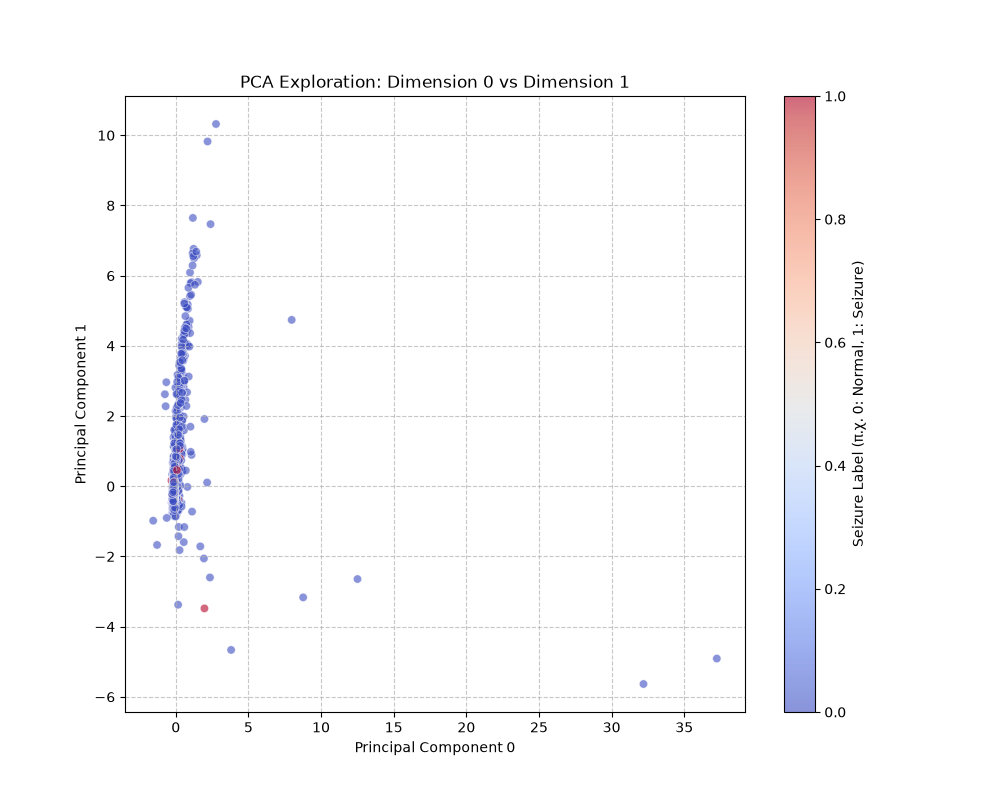

In [19]:
import matplotlib.pyplot as plt

# Επίλεξε ποιες διαστάσεις του PCA θέλεις να συγκρίνεις (ξεκινούν από το 0)
# Η διάσταση 0 εξηγεί τη μεγαλύτερη διακύμανση, η 1 τη δεύτερη μεγαλύτερη κ.ο.κ.
dim1 = 0
dim2 = 1

plt.figure(figsize=(10, 8))

# Υποθέτω ότι οι ετικέτες σου βρίσκονται σε μια μεταβλητή όπως train_labels ή labels
# (Προσάρμοσε το 'labels' παρακάτω στο όνομα της μεταβλητής που περιέχει τα labels των train_data σου)
# Η παράμετρος c=labels καθορίζει το χρώμα βάσει της κλάσης
# Η παράμετρος alpha=0.6 κάνει τις τελείες ημιδιαφανείς για να βλέπεις πού υπάρχει επικάλυψη
scatter = plt.scatter(train_data[:, dim1], train_data[:, dim2], 
                      c=train_labels, cmap='coolwarm', alpha=0.6, edgecolors='w', linewidth=0.5)

plt.title(f'PCA Exploration: Dimension {dim1} vs Dimension {dim2}')
plt.xlabel(f'Principal Component {dim1}')
plt.ylabel(f'Principal Component {dim2}')

# Προσθήκη μπάρας χρωμάτων για να καταλαβαίνεις τι σημαίνει το κάθε χρώμα
plt.colorbar(scatter, label='Seizure Label (π.χ. 0: Normal, 1: Seizure)')
plt.grid(True, linestyle='--', alpha=0.7)

plt.show()

# Create a Model
**Report:** Part 3.3

--- Εφαρμογή SMOTE στο Training Set ---
Παλιά κατανομή Train Set:
Normal (0): 2745 | Seizure (1): 136

Νέα κατανομή Train Set (μετά το SMOTE):
Κλάση 0: 2745 δείγματα
Κλάση 1: 2745 δείγματα

--- Εκπαίδευση & Αξιολόγηση: Logistic Regression ---

Confusion Matrix (Console):
[[661  30]
 [  6  24]]

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.99      0.96      0.97       691
 Seizure (1)       0.44      0.80      0.57        30

    accuracy                           0.95       721
   macro avg       0.72      0.88      0.77       721
weighted avg       0.97      0.95      0.96       721


--- Εκπαίδευση & Αξιολόγηση: SVM (RBF Kernel) ---


C:\Users\owner\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Confusion Matrix (Console):
[[689   2]
 [ 15  15]]

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.98      1.00      0.99       691
 Seizure (1)       0.88      0.50      0.64        30

    accuracy                           0.98       721
   macro avg       0.93      0.75      0.81       721
weighted avg       0.97      0.98      0.97       721

Εμφάνιση Γραφημάτων...


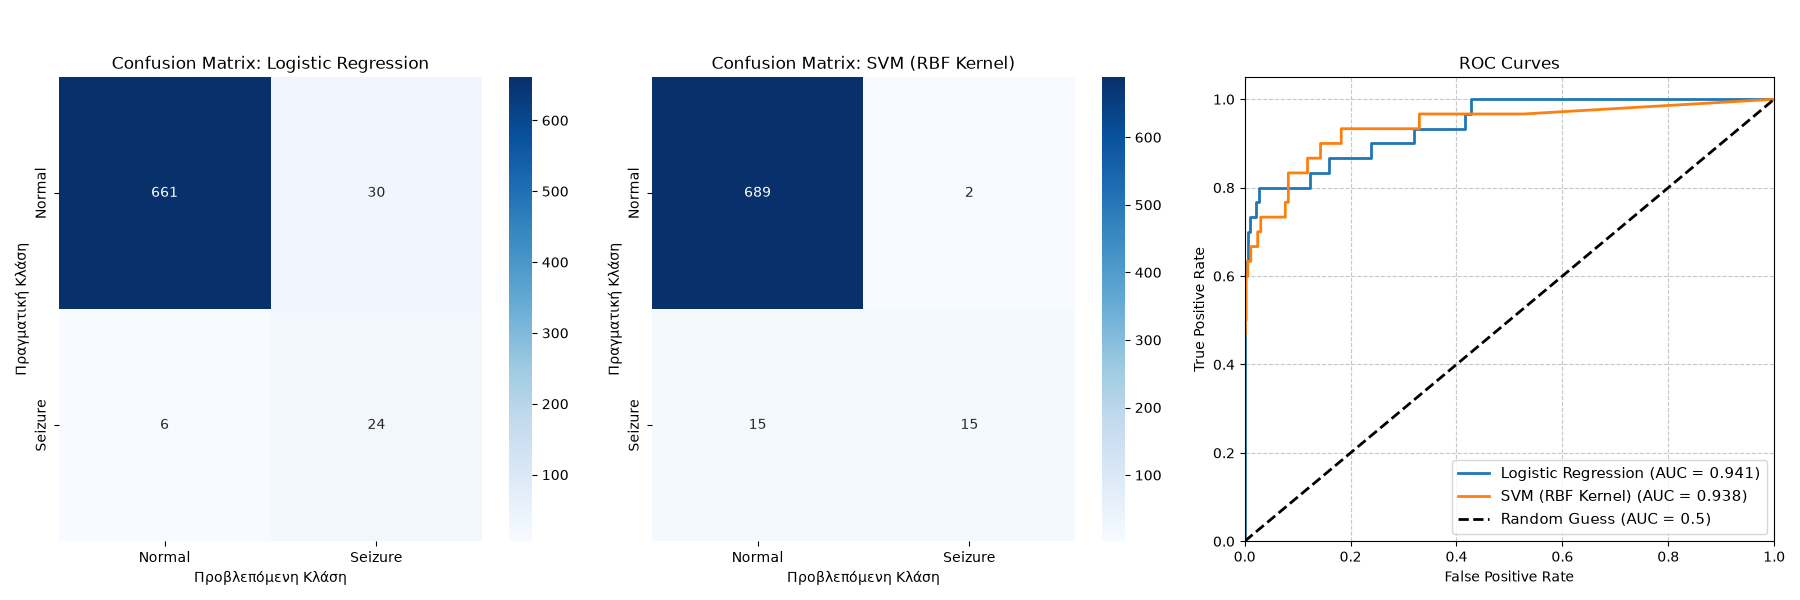

In [20]:
import matplotlib.pyplot as plt

import seaborn as sns

import numpy as np

from sklearn.linear_model import LogisticRegression

from sklearn.svm import SVC

from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc

from imblearn.over_sampling import SMOTE



# --- Δημιουργία Binary Labels για Train και Test ---

train_binary_labels = (train_labels > 0.5).astype(int)

test_binary_labels = (test_labels > 0.5).astype(int)



# Ορισμός των ταξινομητών

classifiers = {

    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=1000),

    "SVM (RBF Kernel)": SVC(kernel='rbf', gamma='auto', class_weight='balanced', C=2.0, probability=True)

}



# --- ΝΕΟ: Ένα ενιαίο γράφημα με 1 σειρά και 3 στήλες ---

fig, axes = plt.subplots(1, 3, figsize=(18, 6))



print("--- Εφαρμογή SMOTE στο Training Set ---")



# 1. Αρχικοποίηση του SMOTE

smote = SMOTE(random_state=42)



# 2. Εφαρμογή ΜΟΝΟ στα δεδομένα εκπαίδευσης 

train_data_smote, train_binary_labels_smote = smote.fit_resample(train_data, train_binary_labels)



# 3. Έλεγχος της νέας κατανομής

unique, counts = np.unique(train_binary_labels_smote, return_counts=True)

print("Παλιά κατανομή Train Set:")

print(f"Normal (0): {np.sum(train_binary_labels == 0)} | Seizure (1): {np.sum(train_binary_labels == 1)}")



print("\nΝέα κατανομή Train Set (μετά το SMOTE):")

for cls, count in zip(unique, counts):

    print(f"Κλάση {cls}: {count} δείγματα")

    

for idx, (name, clf) in enumerate(classifiers.items()):

    print(f"\n==================================================")

    print(f"--- Εκπαίδευση & Αξιολόγηση: {name} ---")

    

    # Εκπαίδευση του μοντέλου με τα δεδομένα του SMOTE

    clf.fit(train_data_smote, train_binary_labels_smote)

    

    # Πρόβλεψη των τελικών κλάσεων (0 ή 1) στο Test Set

    predictions = clf.predict(test_data)

    

    # Πρόβλεψη των πιθανοτήτων (για την ROC Curve)

    probas = clf.predict_proba(test_data)[:, 1]

    

    # Υπολογισμός Confusion Matrix

    cm = confusion_matrix(test_binary_labels, predictions)

    

    print("\nConfusion Matrix (Console):")

    print(cm)

    

    print("\nClassification Report:")

    print(classification_report(test_binary_labels, predictions, target_names=['Normal (0)', 'Seizure (1)']))

    

    # --- Σχεδιασμός Confusion Matrix Heatmap στις στήλες 0 και 1 ---

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], 

                xticklabels=['Normal', 'Seizure'], yticklabels=['Normal', 'Seizure'])

    axes[idx].set_title(f'Confusion Matrix: {name}')

    axes[idx].set_ylabel('Πραγματική Κλάση')

    axes[idx].set_xlabel('Προβλεπόμενη Κλάση')

    

    # --- Υπολογισμός και σχεδιασμός ROC Curve στη στήλη 2 ---

    fpr, tpr, thresholds = roc_curve(test_binary_labels, probas)

    roc_auc = auc(fpr, tpr)

    axes[2].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')



print("==================================================")

print("Εμφάνιση Γραφημάτων...")



# --- Τελικές Ρυθμίσεις για την ROC Curve (στήλη 2) ---

axes[2].plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess (AUC = 0.5)')

axes[2].set_xlim([0.0, 1.0])

axes[2].set_ylim([0.0, 1.05])

axes[2].set_xlabel('False Positive Rate')

axes[2].set_ylabel('True Positive Rate')

axes[2].set_title('ROC Curves')

axes[2].legend(loc="lower right", fontsize=11)

axes[2].grid(True, linestyle='--', alpha=0.7)



# --- Τελικές Ρυθμίσεις Ενιαίου Γραφήματος ---

fig.suptitle('Αξιολόγηση Μοντέλων: Confusion Matrices & ROC Curves', fontsize=18, y=1.05)

fig.tight_layout()



# Εμφανίζει πλέον και τα 3 γραφήματα μαζί σε 1 παράθυρο

plt.show() 


--- Στατιστικά Εφαρμογής SMOTE ---
Παλιά κατανομή Train Set:
Normal (0): 2745 | Seizure (1): 136

Νέα κατανομή Train Set (όπως θα εφαρμόζεται εσωτερικά στα Pipelines):
Κλάση 0: 2745 δείγματα
Κλάση 1: 2745 δείγματα

--- Εκπαίδευση & Αξιολόγηση: Logistic Regression ---

Confusion Matrix (Console):
[[661  30]
 [  6  24]]

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.99      0.96      0.97       691
 Seizure (1)       0.44      0.80      0.57        30

    accuracy                           0.95       721
   macro avg       0.72      0.88      0.77       721
weighted avg       0.97      0.95      0.96       721


--- Εκπαίδευση & Αξιολόγηση: SVM (GridSearch Optimized) ---
Fitting 3 folds for each of 12 candidates, totalling 36 fits


C:\Users\owner\anaconda3\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(



Βέλτιστες Παράμετροι SVM: {'svm__C': 0.1, 'svm__gamma': 0.01}

Confusion Matrix (Console):
[[671  20]
 [  7  23]]

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.99      0.97      0.98       691
 Seizure (1)       0.53      0.77      0.63        30

    accuracy                           0.96       721
   macro avg       0.76      0.87      0.81       721
weighted avg       0.97      0.96      0.97       721

Εμφάνιση Γραφημάτων...


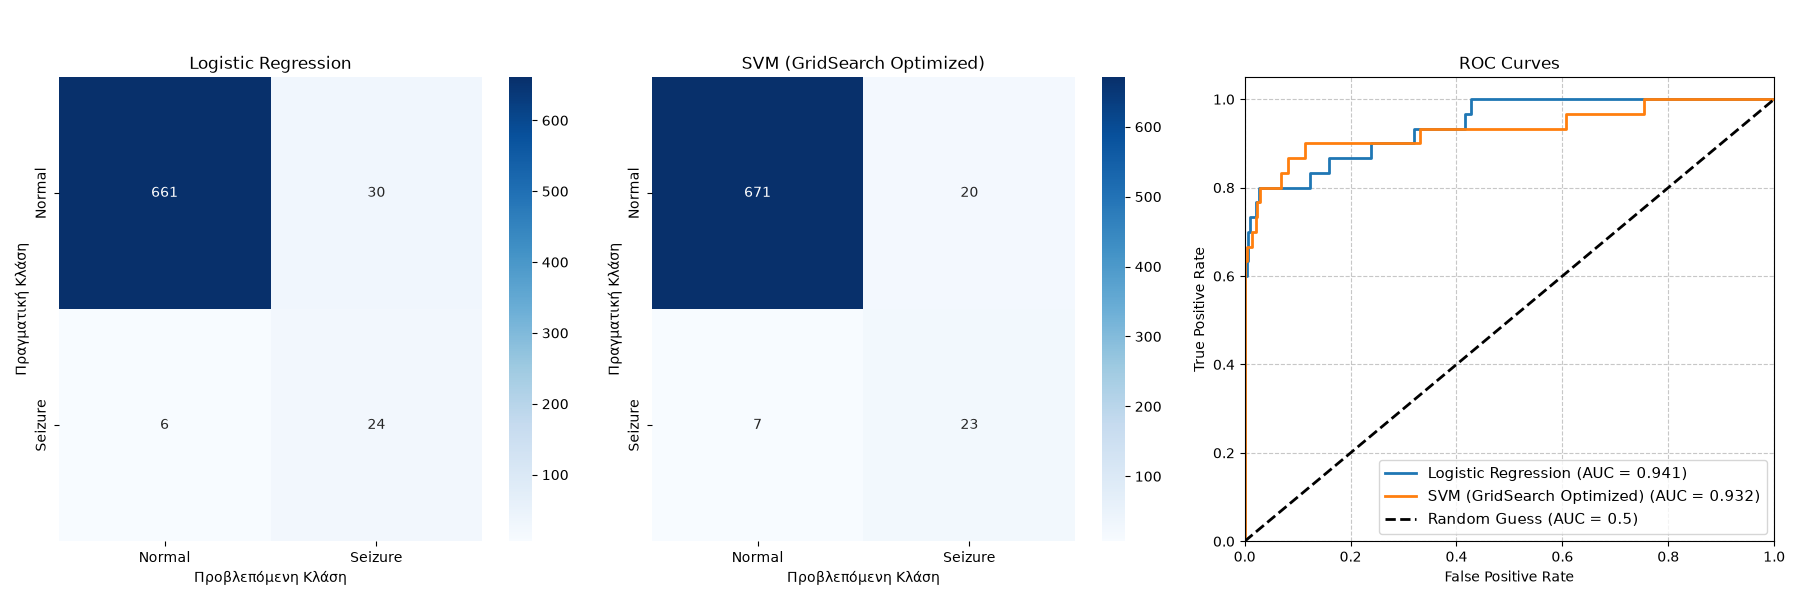

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.model_selection import GridSearchCV

# --- Δημιουργία Binary Labels για Train και Test ---
train_binary_labels = (train_labels > 0.5).astype(int)
test_binary_labels = (test_labels > 0.5).astype(int)

# --- 1. Ορισμός των Pipelines (Ενσωμάτωση SMOTE και Ταξινομητή) ---
pipeline_logreg = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('logreg', LogisticRegression(class_weight='balanced', max_iter=1000))
])

pipeline_svm = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(kernel='rbf', class_weight='balanced', probability=True))
])

# --- 2. Ορισμός παραμέτρων για το Grid Search του SVM ---
param_grid_svm = {
    'svm__C': [0.1, 1, 10, 100],
    'svm__gamma': ['scale', 0.1, 0.01]
}

# Ρύθμιση του GridSearchCV με στόχο τη μεγιστοποίηση του Recall
grid_svm = GridSearchCV(
    estimator=pipeline_svm,
    param_grid=param_grid_svm,
    scoring='recall', 
    cv=3,       # 3-fold cross validation για εξοικονόμηση χρόνου
    n_jobs=-1,  # Χρήση όλων των πυρήνων
    verbose=1
)

# Ορισμός των ταξινομητών για το loop
classifiers = {
    "Logistic Regression": pipeline_logreg,
    "SVM (GridSearch Optimized)": grid_svm
}

# --- Προετοιμασία γραφημάτων ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

print("--- Στατιστικά Εφαρμογής SMOTE ---")
# Δημιουργούμε ένα στιγμιότυπο του SMOTE μόνο για να τυπώσουμε τις πληροφορίες κατανομής
smote_dummy = SMOTE(random_state=42)
_, train_binary_labels_smote_dummy = smote_dummy.fit_resample(train_data, train_binary_labels)

unique, counts = np.unique(train_binary_labels_smote_dummy, return_counts=True)
print("Παλιά κατανομή Train Set:")
print(f"Normal (0): {np.sum(train_binary_labels == 0)} | Seizure (1): {np.sum(train_binary_labels == 1)}")
print("\nΝέα κατανομή Train Set (όπως θα εφαρμόζεται εσωτερικά στα Pipelines):")
for cls, count in zip(unique, counts):
    print(f"Κλάση {cls}: {count} δείγματα")
    
for idx, (name, clf) in enumerate(classifiers.items()):
    print(f"\n==================================================")
    print(f"--- Εκπαίδευση & Αξιολόγηση: {name} ---")
    
    # ΣΗΜΑΝΤΙΚΟ: Πλέον τροφοδοτούμε τα ΑΡΧΙΚΑ δεδομένα. 
    # Τα Pipelines αναλαμβάνουν το SMOTE εσωτερικά!
    clf.fit(train_data, train_binary_labels)
    
    # Αν είναι το GridSearch, τυπώνουμε τις καλύτερες παραμέτρους
    if isinstance(clf, GridSearchCV):
        print(f"\nΒέλτιστες Παράμετροι SVM: {clf.best_params_}")
    
    # Πρόβλεψη των τελικών κλάσεων (0 ή 1) στο Test Set
    predictions = clf.predict(test_data)
    
    # Πρόβλεψη των πιθανοτήτων (για την ROC Curve)
    probas = clf.predict_proba(test_data)[:, 1]
    
    # Υπολογισμός Confusion Matrix
    cm = confusion_matrix(test_binary_labels, predictions)
    
    print("\nConfusion Matrix (Console):")
    print(cm)
    
    print("\nClassification Report:")
    print(classification_report(test_binary_labels, predictions, target_names=['Normal (0)', 'Seizure (1)']))
    
    # --- Σχεδιασμός Confusion Matrix Heatmap στις στήλες 0 και 1 ---
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], 
                xticklabels=['Normal', 'Seizure'], yticklabels=['Normal', 'Seizure'])
    axes[idx].set_title(f'{name}')
    axes[idx].set_ylabel('Πραγματική Κλάση')
    axes[idx].set_xlabel('Προβλεπόμενη Κλάση')
    
    # --- Υπολογισμός και σχεδιασμός ROC Curve στη στήλη 2 ---
    fpr, tpr, thresholds = roc_curve(test_binary_labels, probas)
    roc_auc = auc(fpr, tpr)
    axes[2].plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

print("==================================================")
print("Εμφάνιση Γραφημάτων...")

# --- Τελικές Ρυθμίσεις για την ROC Curve (στήλη 2) ---
axes[2].plot([0, 1], [0, 1], 'k--', lw=2, label='Random Guess (AUC = 0.5)')
axes[2].set_xlim([0.0, 1.0])
axes[2].set_ylim([0.0, 1.05])
axes[2].set_xlabel('False Positive Rate')
axes[2].set_ylabel('True Positive Rate')
axes[2].set_title('ROC Curves')
axes[2].legend(loc="lower right", fontsize=11)
axes[2].grid(True, linestyle='--', alpha=0.7)

# --- Τελικές Ρυθμίσεις Ενιαίου Γραφήματος ---
fig.suptitle('Αξιολόγηση Μοντέλων: Confusion Matrices & ROC Curves', fontsize=18, y=1.05)
fig.tight_layout()

plt.show()


# Evaluation
Evaluate accuracy, sensitivity, specificity, confusion matrix.
What do these measures tell us about the performance of our model?

Check which features were most relevant.

**Report:** Part 3.3